# AgriCLIP Attention-Guided Prompt Generation for Fine-tuned SAM2

## Objective

This notebook implements an attention-guided prompt generation pipeline for vegetation segmentation.

Pipeline:

RGB Image
→ DINO ResNet50
→ Patch Features
→ VegAnn-trained AgriCLIP Aligner
→ Patch-level Semantic Embeddings
→ Attention Map
→ Candidate Vegetation Mask
→ Auto Bounding Box
→ Three Positive Points
→ Fine-tuned SAM2
→ Final Vegetation Segmentation

Unlike notebook # 17 experiments, AgriCLIP is **not used as a detector**.

Instead, it provides semantic attention that guides SAM2 prompts.

In [276]:
#Imports 
import os
import sys
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt

import torch
import torch.nn.functional as F

from PIL import Image

from datasets import load_dataset

from transformers import (
    Sam2Model,
    Sam2Processor,
)

from torchvision import transforms

from tqdm.auto import tqdm

In [277]:
#Paths registry 
PROJECT_ROOT = Path("/home/zahranadeem/thesis")

MODEL_NAME = "facebook/sam2-hiera-large"

###############################################

AGRICLIP_ROOT = (
    PROJECT_ROOT
    / "agriclip_sam2"
    / "AgriCLIP"
)

ALIGNMENT_DIR = (
    AGRICLIP_ROOT
    / "AgriCLIP_alignment"
)

ALIGNER_PATH = (
    PROJECT_ROOT
    / "vegann_aligner.pth"
)

SAM2_CHECKPOINT = (
    PROJECT_ROOT
    / "sam2_vegann_checkpoints"
    / "best_sam2_vegann_mask_decoder.pt"
)

OUTPUT_DIR = (
    PROJECT_ROOT
    / "results"
    / "agriclip_attention_guided_sam2"
)

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)

print("Project:", PROJECT_ROOT)
print("AgriCLIP:", AGRICLIP_ROOT)
print("Aligner:", ALIGNER_PATH)
print("SAM2:", SAM2_CHECKPOINT)

Project: /home/zahranadeem/thesis
AgriCLIP: /home/zahranadeem/thesis/agriclip_sam2/AgriCLIP
Aligner: /home/zahranadeem/thesis/vegann_aligner.pth
SAM2: /home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt


In [278]:
#Checking the device 
device = torch.device(
    "cuda"
    if torch.cuda.is_available()
    else "cpu"
)

print(device)

cuda


In [279]:
#Loading VegAnn and split 
vegann = load_dataset(
    "simonMadec/VegAnn"
)

split = vegann["train"].train_test_split(
    test_size=0.20,
    seed=42
)

train_hf = split["train"]
val_hf = split["test"]

print(len(train_hf))
print(len(val_hf))

3020
755


In [280]:
#Detecting image and mask coloums 
columns = vegann["train"].column_names

IMAGE_KEY = next(
    x
    for x in columns
    if x in ["image", "images", "rgb"]
)

MASK_KEY = next(
    x
    for x in columns
    if x in [
        "mask",
        "masks",
        "label",
        "labels",
        "segmentation_mask",
    ]
)

print(IMAGE_KEY)
print(MASK_KEY)

image
mask


In [281]:
#Image helper
def get_image(index, split=val_hf):

    sample = split[index]

    image = sample[IMAGE_KEY]

    if not isinstance(image, Image.Image):
        image = Image.fromarray(np.array(image))

    return image.convert("RGB")


def get_mask(index, split=val_hf):

    sample = split[index]

    mask = np.array(sample[MASK_KEY])

    mask = (mask > 0).astype(np.uint8)

    return mask

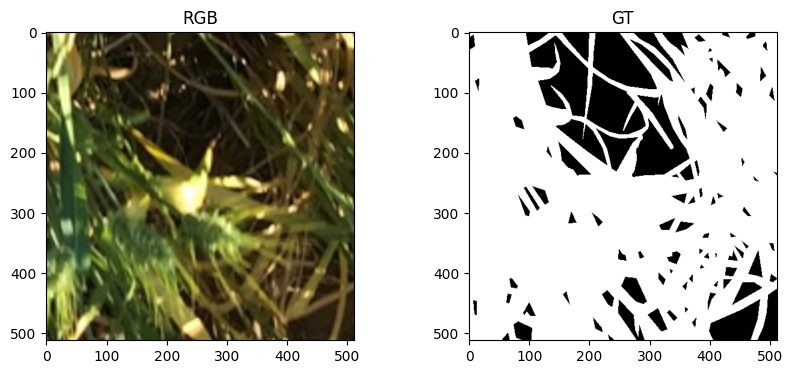

In [282]:
#Visualize image and mask 
image = get_image(0)
mask = get_mask(0)

plt.figure(figsize=(10,4))

plt.subplot(121)
plt.imshow(image)
plt.title("RGB")

plt.subplot(122)
plt.imshow(mask,cmap="gray")
plt.title("GT")

plt.show()

In [283]:
#Transform the image 
IMAGENET_MEAN = [
    0.485,
    0.456,
    0.406,
]

IMAGENET_STD = [
    0.229,
    0.224,
    0.225,
]

dino_transform = transforms.Compose([

    transforms.Resize(
        (224,224)
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        IMAGENET_MEAN,
        IMAGENET_STD,
    ),
])

## Import AGRICLIP and use it as an attention guided prompt generator
using DINO  ResNET50 as the visual backbone
No need to extract a single global feature vector
Extracting the 7x7 spatial feature map from last conv layer 
each spatial location -? ome image patch

In [284]:
sys.path.append(
    str(ALIGNMENT_DIR)
)

from TextToConcept import TextToConcept
from LinearAligner import LinearAligner

print("AgriCLIP imported successfully.")

AgriCLIP imported successfully.


In [285]:
#Load DINO 
dino_model = torch.hub.load(
    "facebookresearch/dino:main",
    "dino_resnet50",
    pretrained=True,
)

dino_model.eval()
dino_model.to(device)

for parameter in dino_model.parameters():
    parameter.requires_grad = False

print("DINO loaded.")

DINO loaded.


Using cache found in /home/zahranadeem/.cache/torch/hub/facebookresearch_dino_main


In [286]:
#Registering forward hook 
feature_map = None

def hook_fn(module, input, output):

    global feature_map

    feature_map = output


hook_handle = dino_model.layer4.register_forward_hook(
    hook_fn
)

print("Forward hook registered.")

Forward hook registered.


In [287]:
#extracting 7x7 feature map 
@torch.no_grad()
def extract_patch_features(image):

    global feature_map

    tensor = dino_transform(image)

    tensor = tensor.unsqueeze(0).to(device)

    _ = dino_model(tensor)

    fmap = feature_map.squeeze(0)

    fmap = fmap.permute(
        1,
        2,
        0,
    )

    fmap = fmap.reshape(
        -1,
        fmap.shape[-1],
    )

    return fmap.cpu().numpy()

In [288]:
#Testing the feature extraction 
patches = extract_patch_features(
    image
)

print(patches.shape)

(49, 2048)


## — Load the VegAnn-trained AgriCLIP Aligner

The aligner projects DINO visual embeddings into the AgriCLIP semantic space.

Each of the 49 DINO patches becomes a semantic vegetation representation.

In [289]:
text_to_concept = TextToConcept(
    dino_model,
    "dino_resnet50",
)

text_to_concept.load_linear_aligner(
    str(ALIGNER_PATH)
)

aligner = text_to_concept.linear_aligner

print("VegAnn aligner loaded.")

VegAnn aligner loaded.


In [290]:
#Align every patch 
def align_patch_features(
    patch_features,
):

    patches = torch.from_numpy(
        patch_features
    ).float().to(device)

    W = aligner.W.float()

    b = aligner.b.float()

    aligned = patches @ W.T + b

    return aligned

In [291]:
#testing aligner 
aligned = align_patch_features(
    patches
)

print(aligned.shape)

torch.Size([49, 512])


## Step 3 — Define Vegetation and Background Prompts

Unlike previous experiments, AgriCLIP is **not used to classify the whole image**.

Instead, every aligned patch embedding is compared with semantic vegetation and background prompts.

The difference between positive and negative similarities becomes the attention score.

In [292]:
#Prompts 
POSITIVE_PROMPTS = [

    "A crop field populated by healthy plants, captured from a nadir view using a handheld camera.",

    "An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.",

    "A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.",

    "An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.",

    "Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.",

    "Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera."

]
NEGATIVE_PROMPTS = [

    "Bare agricultural soil, captured from a nadir view using a handheld camera.",

    "An empty agricultural field without vegetation, captured from a nadir view using a handheld camera.",

    "Dry exposed soil, captured from a nadir view using a handheld camera.",

    "Agricultural land without crops, captured from a nadir view using a handheld camera.",

    "Only background soil visible, captured from a nadir view using a handheld camera.",

    "A field without vegetation, captured from a nadir view using a handheld camera."

]


In [293]:
print("Positive prompts\n")

for p in POSITIVE_PROMPTS:
    print("+", p)

print("\nNegative prompts\n")

for p in NEGATIVE_PROMPTS:
    print("-", p)

Positive prompts

+ A crop field populated by healthy plants, captured from a nadir view using a handheld camera.
+ An agricultural scene showing healthy crops growing in the field, captured from a nadir view using a handheld camera.
+ A field image containing healthy crop vegetation, captured from a nadir view using a handheld camera.
+ An aerial agricultural image of dense green crop plants, captured from a nadir view using a handheld camera.
+ Healthy crop canopy covering the field, captured from a nadir view using a handheld camera.
+ Agricultural vegetation viewed from above, captured from a nadir view using a handheld camera.

Negative prompts

- Bare agricultural soil, captured from a nadir view using a handheld camera.
- An empty agricultural field without vegetation, captured from a nadir view using a handheld camera.
- Dry exposed soil, captured from a nadir view using a handheld camera.
- Agricultural land without crops, captured from a nadir view using a handheld camera.
- 

In [294]:
positive_embeddings = []

for prompt in POSITIVE_PROMPTS:

    embedding = text_to_concept.encode_text([[prompt]])

    positive_embeddings.append(
        embedding.squeeze().float()
    )

positive_embeddings = torch.stack(
    positive_embeddings,
    dim=0
)


negative_embeddings = []

for prompt in NEGATIVE_PROMPTS:

    embedding = text_to_concept.encode_text([[prompt]])

    negative_embeddings.append(
        embedding.squeeze().float()
    )

negative_embeddings = torch.stack(
    negative_embeddings,
    dim=0
)


print(positive_embeddings.shape)
print(negative_embeddings.shape)

torch.Size([6, 512])
torch.Size([6, 512])


In [295]:
#Average these prompt embeddings 
positive_embedding = positive_embeddings.mean(dim=0)

negative_embedding = negative_embeddings.mean(dim=0)

print(positive_embedding.shape)

torch.Size([512])


## Compute Patch-Level Semantic Attention

Each aligned DINO patch embedding is compared with

- vegetation prompts
- background prompts

using cosine similarity.

For every patch:

Attention = Positive Similarity − Negative Similarity

Higher values indicate patches that are more likely to contain vegetation.

The resulting 49 scores are reshaped into a 7×7 attention map.

In [296]:
#Computing cosine similarity 

def compute_patch_attention(
    aligned_features,
    positive_embeddings,
    negative_embeddings,
    temperature=0.07,  # Standard CLIP temperature scales logits properly
    topk_ratio=0.30,   # Keep only the top 30% of patches
):
    aligned_features = F.normalize(aligned_features, dim=1)
    positive_embeddings = F.normalize(positive_embeddings, dim=1)
    negative_embeddings = F.normalize(negative_embeddings, dim=1)

    # 49 × 6
    positive_scores = torch.matmul(aligned_features, positive_embeddings.T)
    # 49 × 6
    negative_scores = torch.matmul(aligned_features, negative_embeddings.T)

    # Best matching positive and negative values per patch
    pos_max = positive_scores.max(dim=1).values
    neg_max = negative_scores.max(dim=1).values

    # STAGE 1: Apply Softmax across the binary decision (Veg vs Non-Veg)
    # This prevents the min/max variance collapse you experienced
    stacked_sims = torch.stack([pos_max, neg_max], dim=-1) / temperature
    probabilities = F.softmax(stacked_sims, dim=-1)
    attention = probabilities[:, 0]  # Grab the positive vegetation probability

    # STAGE 2: Top-K Suppression to eliminate low-level background noise
    topk_count = int(attention.numel() * topk_ratio)
    topk_values, _ = torch.topk(attention, k=topk_count)
    cutoff_threshold = topk_values[-1]
    
    # Force everything below the top 30% of patches to be absolute zero
    attention = torch.where(attention >= cutoff_threshold, attention, torch.zeros_like(attention))

    attention = attention.reshape(7, 7)
    return attention


"""def compute_patch_attention(
    aligned_features,
    positive_embeddings,
    negative_embeddings,
):

    aligned_features = F.normalize(
        aligned_features,
        dim=1,
    )

    positive_embeddings = F.normalize(
        positive_embeddings,
        dim=1,
    )

    negative_embeddings = F.normalize(
        negative_embeddings,
        dim=1,
    )

    # 49 × 6
    positive_scores = torch.matmul(
        aligned_features,
        positive_embeddings.T,
    )

    # 49 × 6
    negative_scores = torch.matmul(
        aligned_features,
        negative_embeddings.T,
    )

    # Best matching positive prompt
    positive_scores = positive_scores.max(
        dim=1
    ).values

    # Best matching negative prompt
    negative_scores = negative_scores.max(
        dim=1
    ).values

    attention = positive_scores - negative_scores

    attention = attention.reshape(
        7,
        7,
    )

    return attention"""
    
    


'def compute_patch_attention(\n    aligned_features,\n    positive_embeddings,\n    negative_embeddings,\n):\n\n    aligned_features = F.normalize(\n        aligned_features,\n        dim=1,\n    )\n\n    positive_embeddings = F.normalize(\n        positive_embeddings,\n        dim=1,\n    )\n\n    negative_embeddings = F.normalize(\n        negative_embeddings,\n        dim=1,\n    )\n\n    # 49 × 6\n    positive_scores = torch.matmul(\n        aligned_features,\n        positive_embeddings.T,\n    )\n\n    # 49 × 6\n    negative_scores = torch.matmul(\n        aligned_features,\n        negative_embeddings.T,\n    )\n\n    # Best matching positive prompt\n    positive_scores = positive_scores.max(\n        dim=1\n    ).values\n\n    # Best matching negative prompt\n    negative_scores = negative_scores.max(\n        dim=1\n    ).values\n\n    attention = positive_scores - negative_scores\n\n    attention = attention.reshape(\n        7,\n        7,\n    )\n\n    return attention'

In [297]:
#Generate first attention map 
attention = compute_patch_attention(
    aligned,
    positive_embeddings,
    negative_embeddings,
)

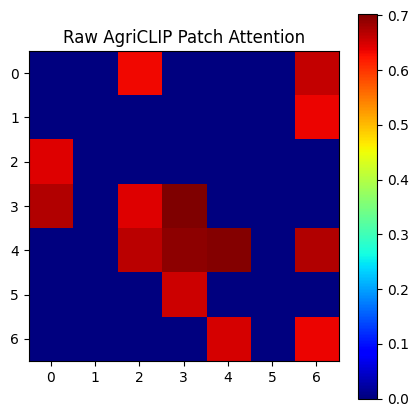

In [298]:
#Visualize raw attention 
plt.figure(figsize=(5,5))

plt.imshow(
    attention.cpu(),
    cmap="jet",
)

plt.colorbar()

plt.title(
    "Raw AgriCLIP Patch Attention"
)

plt.show()

In [299]:
#Uosample attention 
H, W = np.array(image).shape[:2]

attention_up = F.interpolate(

    attention.unsqueeze(0).unsqueeze(0),

    size=(H, W),

    mode="bilinear",

    align_corners=False,

).squeeze()

print(attention_up.shape)

torch.Size([512, 512])


In [300]:
#Normalize attention 
attention_np = attention_up.cpu().numpy()

attention_np = (
    attention_np
    - attention_np.min()
)

attention_np = (
    attention_np
    / (
        attention_np.max()
        + 1e-8
    )
)

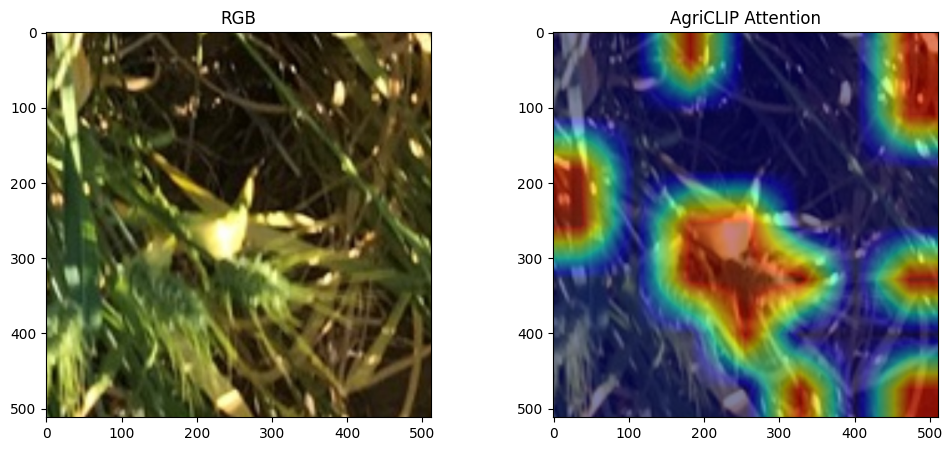

In [301]:
#Overlay heatmap 
plt.figure(figsize=(12,5))

plt.subplot(121)

plt.imshow(image)

plt.title("RGB")

plt.subplot(122)

plt.imshow(image)

plt.imshow(

    attention_np,

    cmap="jet",

    alpha=0.5,

)

plt.title("AgriCLIP Attention")

plt.show()

In [302]:
#generate vegetation from AgriClip not ExG 
"""threshold = np.percentile(
    attention_np,
    75,
)

candidate_mask = (
    attention_np >= threshold
).astype(np.uint8)"""


attention_np = attention_up.cpu().numpy()
attention_np = (attention_np - attention_np.min()) / (attention_np.max() - attention_np.min() + 1e-8)
attention_uint8 = (attention_np * 255).astype(np.uint8)

# STAGE 3: Run Otsu's Binarization to cleanly split Foreground from Background
_, candidate_mask = cv2.threshold(
    attention_uint8, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU
)
# Normalize back to binary 0 or 1
candidate_mask = (candidate_mask > 0).astype(np.uint8)

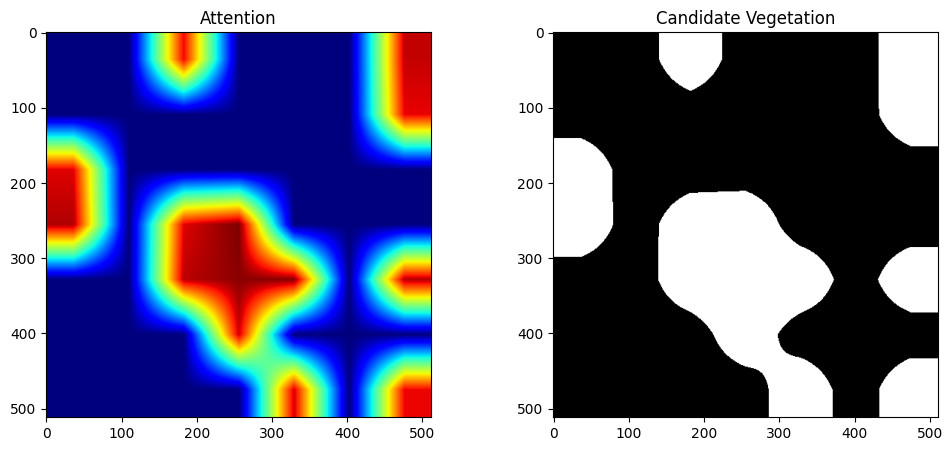

In [303]:
#Visualzie candidate mask 
plt.figure(figsize=(12,5))

plt.subplot(121)

plt.imshow(
    attention_np,
    cmap="jet",
)

plt.title("Attention")

plt.subplot(122)

plt.imshow(
    candidate_mask,
    cmap="gray",
)

plt.title("Candidate Vegetation")

plt.show()

In [304]:
##AutoBox 
ys, xs = np.where(candidate_mask)

if len(xs) == 0:

    H, W = candidate_mask.shape

    auto_box = np.array([
        W//4,
        H//4,
        3*W//4,
        3*H//4,
    ])

else:

    auto_box = np.array([

        xs.min(),

        ys.min(),

        xs.max(),

        ys.max(),

    ])

print(auto_box)


[  0   0 511 511]


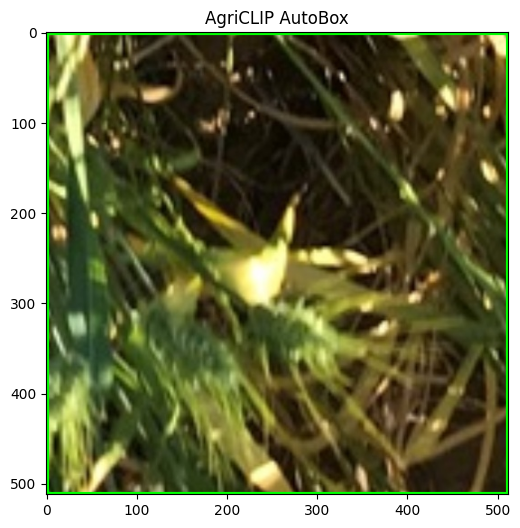

In [305]:
#Visualize AutoBox 
fig, ax = plt.subplots(figsize=(6,6))

ax.imshow(image)

x1, y1, x2, y2 = auto_box

rect = plt.Rectangle(

    (x1,y1),

    x2-x1,

    y2-y1,

    edgecolor="lime",

    linewidth=3,

    fill=False,

)

ax.add_patch(rect)

plt.title("AgriCLIP AutoBox")

plt.show()

In [306]:
print(type(image))

<class 'PIL.Image.Image'>


In [307]:
from pathlib import Path

FINETUNED_SAM2_CHECKPOINT = Path(
    "/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt"
)

print(FINETUNED_SAM2_CHECKPOINT)
print(FINETUNED_SAM2_CHECKPOINT.exists())

/home/zahranadeem/thesis/sam2_vegann_checkpoints/best_sam2_vegann_mask_decoder.pt
True


In [308]:
from transformers import Sam2Processor, Sam2Model

MODEL_NAME = "facebook/sam2-hiera-large"

processor = Sam2Processor.from_pretrained(
    MODEL_NAME
)

sam2 = Sam2Model.from_pretrained(
    MODEL_NAME
)

checkpoint = torch.load(
    FINETUNED_SAM2_CHECKPOINT,
    map_location=device
)

sam2.mask_decoder.load_state_dict(
    checkpoint["mask_decoder_state_dict"]
)

sam2.to(device)
sam2.eval()

print("Fine-tuned SAM2 loaded successfully.")

[transformers] You are using a model of type `sam2_video` to instantiate a model of type `sam2`. This may be expected if you are loading a checkpoint that shares a subset of the architecture (e.g., loading a `sam2_video` checkpoint into `Sam2Model`), but is otherwise not supported and can yield errors. Please verify that the checkpoint is compatible with the model you are instantiating.


Loading weights:   0%|          | 0/741 [00:00<?, ?it/s]

Fine-tuned SAM2 loaded successfully.


In [309]:
#AutoBox from AgriCLIP candidate mask 

def get_auto_box(mask):
    ys, xs = np.where(mask > 0)
    H, W = mask.shape

    if len(xs) == 0:
        return None  # Return None so your pipeline knows to drop it

    x0, y0, x1, y1 = xs.min(), ys.min(), xs.max(), ys.max()

    # STAGE 4: Boundary Safety Check
    # If the box spans the entire image, it breaks SAM2's geometry context. Drop it.
    if (x1 - x0) >= (W - 4) and (y1 - y0) >= (H - 4):
        return None

    return np.array([x0, y0, x1, y1])


"""def get_auto_box(mask):

    ys, xs = np.where(mask > 0)

    H, W = mask.shape

    if len(xs) == 0:

        return np.array([
            0,
            0,
            W - 1,
            H - 1
        ])

    x0 = xs.min()
    y0 = ys.min()
    x1 = xs.max()
    y1 = ys.max()

    return np.array([
        x0,
        y0,
        x1,
        y1
    ])"""

'def get_auto_box(mask):\n\n    ys, xs = np.where(mask > 0)\n\n    H, W = mask.shape\n\n    if len(xs) == 0:\n\n        return np.array([\n            0,\n            0,\n            W - 1,\n            H - 1\n        ])\n\n    x0 = xs.min()\n    y0 = ys.min()\n    x1 = xs.max()\n    y1 = ys.max()\n\n    return np.array([\n        x0,\n        y0,\n        x1,\n        y1\n    ])'

In [310]:
import numpy as np

"""def get_three_positive_points(mask):

    ys, xs = np.where(mask > 0)

    H, W = mask.shape

    if len(xs) == 0:

        return np.array([
            [W//2, H//2],
            [W//3, H//3],
            [2*W//3, 2*H//3]
        ])

    points = []

    points.append([
        int(xs.mean()),
        int(ys.mean())
    ])

    q1 = len(xs)//4

    q3 = (3*len(xs))//4

    points.append([
        int(xs[q1]),
        int(ys[q1])
    ])

    points.append([
        int(xs[q3]),
        int(ys[q3])
    ])

    return np.array(points)"""

def get_three_positive_points(attention_img, mask):
    """
    Selects 3 points from the absolute highest peaks of your attention map 
    inside your valid candidate mask, ensuring correct (X, Y) order.
    """
    H, W = mask.shape
    # Flatten map and sort indices from highest intensity to lowest
    sorted_indices = np.argsort(attention_img.flatten())[::-1]
    
    points = []
    for idx in sorted_indices:
        # divmod on a flat matrix layout: row = idx // W, col = idx % W
        y, x = divmod(idx, W)
        
        # Ensure point is inside our valid binary candidate mask
        if mask[y, x] == 1:
            # Enforce spatial separation so points don't stack on the exact same leaf pixel
            # We measure distance in Euclidean space: sqrt((x1-x2)^2 + (y1-y2)^2)
            if all(np.linalg.norm(np.array([x, y]) - np.array(p)) > 20 for p in points):
                points.append([float(x), float(y)])  # (X=col, Y=row) is Image Space standard
                
        if len(points) == 3:
            break
            
    # Absolute fallback to centers if the attention map failed to find valid mask regions
    while len(points) < 3:
        points.append([float(W // 2), float(H // 2)])
        
    return np.array(points, dtype=np.float32)


In [311]:
#Building SAM2 prompts 
"""auto_box = get_auto_box(
    candidate_mask
)

points = get_three_positive_points(
    candidate_mask
)

labels = np.ones(
    len(points),
    dtype=np.int64
)

print("AutoBox:", auto_box)
print("Points:")
print(points)"""

# Generate prompts using corrected logic
#auto_box = get_auto_box(candidate_mask)
points = get_three_positive_points(attention_np, candidate_mask)
labels = np.ones(len(points), dtype=np.int64)



# 1. Flip your points from [X, Y] to [Y, X]
flipped_points = np.stack([points[:, 1], points[:, 0]], axis=1)

# 2. CRITICAL: Reshape your flipped points to standard 4D HuggingFace batch format
formatted_points = flipped_points.reshape(1, 1, 3, 2)
formatted_labels = labels.reshape(1, 1, 3)
print("--- ISOLATION TEST ---")
print("Points shape passed to processor:", formatted_points.shape)
print("Points coordinates:\n", points)

prompt_kwargs = {
    "images": image,
    "input_points": formatted_points,     # <--- Pass the reshaped 4D array here
    "input_labels": formatted_labels,
    "return_tensors": "pt"
}

if auto_box is not None:
    # 3. CRITICAL: Flip box layout to match your point axis switch:
    # Standard: [x0, y0, x1, y1] -> Flipped: [y0, x0, y1, x1]
    flipped_box = np.array([auto_box[1], auto_box[0], auto_box[3], auto_box[2]])
    
    # Reshape box to standard 3D HuggingFace batch format [Batch=1, Num_prompts=1, Coordinates=4]
    formatted_box = flipped_box.reshape(1, 1, 4)
    prompt_kwargs["input_boxes"] = formatted_box
    print("Feeding SAM2: Validated Flipped Box and Flipped Coordinates aligned.")
else:
    print("Feeding SAM2: Flipped Points Only.")

inputs = processor(**prompt_kwargs)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = sam2(**inputs)



--- ISOLATION TEST ---
Points shape passed to processor: (1, 1, 3, 2)
Points coordinates:
 [[255. 256.]
 [255. 277.]
 [255. 298.]]
Feeding SAM2: Validated Flipped Box and Flipped Coordinates aligned.


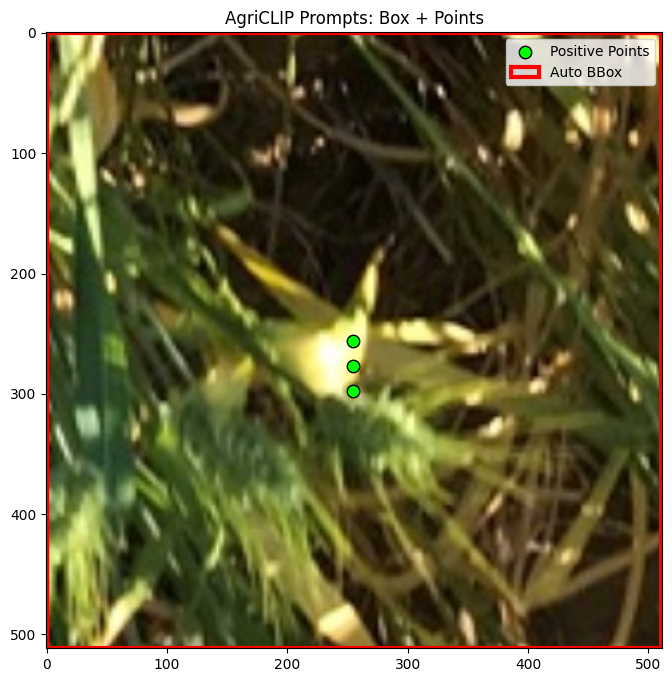

In [312]:
plt.figure(figsize=(8, 8))
plt.imshow(image)

# 1. Always plot the 3 positive points
plt.scatter(
    points[:, 0],
    points[:, 1],
    c="lime",
    s=80,
    edgecolors="black",
    label="Positive Points"
)

# 2. Only attempt to unpack and plot the box if it exists
if auto_box is not None:
    x0, y0, x1, y1 = auto_box
    
    plt.gca().add_patch(
        plt.Rectangle(
            (x0, y0),
            x1 - x0,
            y1 - y0,
            edgecolor="red",
            facecolor="none",
            lw=3,
            label="Auto BBox"
        )
    )
    plt.title("AgriCLIP Prompts: Box + Points")
else:
    plt.title("AgriCLIP Prompts: Points Only (Box Suppressed)")

plt.legend()
plt.show()


In [313]:
print("processor" in globals())
print("sam2" in globals())
print("image" in globals())
print("sample_image" in globals())
print("candidate_mask" in globals())

True
True
True
False
True


In [314]:
#Run Fine Tuned SAM2 
"""inputs = processor(

    images=image,

    input_boxes=[[auto_box]],

    input_points=[[points]],

    input_labels=[[labels]],

    return_tensors="pt"

)

inputs = {

    k: v.to(device)

    for k,v in inputs.items()

}

with torch.no_grad():

    outputs = sam2(**inputs)"""

# Build configuration conditionally based on bounding box safety status
prompt_kwargs = {
    "images": image,
    "input_points": [[points]],
    "input_labels": [[labels]],
    "return_tensors": "pt"
}

# Only pass input_boxes if the auto_box passed our safety validations
if auto_box is not None:
    prompt_kwargs["input_boxes"] = [[auto_box]]
    print("Prompts: Using AutoBox and 3 Points")
else:
    print("Prompts: Image-wide mask detected. Discarding Box, relying ONLY on 3 Points")

inputs = processor(**prompt_kwargs)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = sam2(**inputs)




Prompts: Using AutoBox and 3 Points


In [315]:
for k in inputs.keys():
    print(k)

pixel_values
original_sizes
input_points
input_labels
input_boxes


In [316]:
import transformers

print(transformers.__version__)

5.14.1


In [317]:
print(inputs.keys())

for k, v in inputs.items():

    if hasattr(v, "shape"):

        print(k, v.shape)

    else:

        print(k, type(v))

dict_keys(['pixel_values', 'original_sizes', 'input_points', 'input_labels', 'input_boxes'])
pixel_values torch.Size([1, 3, 1024, 1024])
original_sizes torch.Size([1, 2])
input_points torch.Size([1, 1, 3, 2])
input_labels torch.Size([1, 1, 3])
input_boxes torch.Size([1, 1, 4])


In [318]:
print(outputs.keys())

odict_keys(['iou_scores', 'pred_masks', 'object_score_logits', 'image_embeddings'])


In [319]:
print(outputs.pred_masks.shape)

torch.Size([1, 1, 3, 256, 256])


In [320]:
print(
    hasattr(
        processor.image_processor,
        "post_process_masks"
    )
)

True


In [321]:
#Decode prediction 

# ==========================================
# 1. Run Fine Tuned SAM2 (From your script)
# ==========================================
inputs = processor(**prompt_kwargs)
inputs = {k: v.to(device) for k, v in inputs.items()}

with torch.no_grad():
    outputs = sam2(**inputs)

# ==========================================
# 2. Decode prediction (REPLACE OLD BLOCK WITH THIS)
# ==========================================

# Choose mask with highest predicted IoU score
best_mask_idx = outputs.iou_scores[0, 0].argmax().item()

# Extract the raw logit mask
raw_mask = outputs.pred_masks[0, 0, best_mask_idx]

# Grab original image dimensions from PIL Image or Array
orig_W, orig_H = image.size if hasattr(image, 'size') else (image.shape[1], image.shape[0])

# Upscale logits cleanly using bilinear interpolation before thresholding
resized_logits = F.interpolate(
    raw_mask.unsqueeze(0).unsqueeze(0),
    size=(int(orig_H), int(orig_W)),
    mode="bilinear",
    align_corners=False
).squeeze()

# Convert logits to binary mask via Sigmoid or 0-threshold check
pred_mask = (torch.sigmoid(resized_logits) > 0.5).cpu().numpy().astype(np.uint8)

# ==========================================
# 3. Ready for Evaluation / Metrics
# ==========================================
# Now your 'pred_mask' variable is perfectly sized and formatted 
# to compare against your ground truth mask for IoU and Dice!





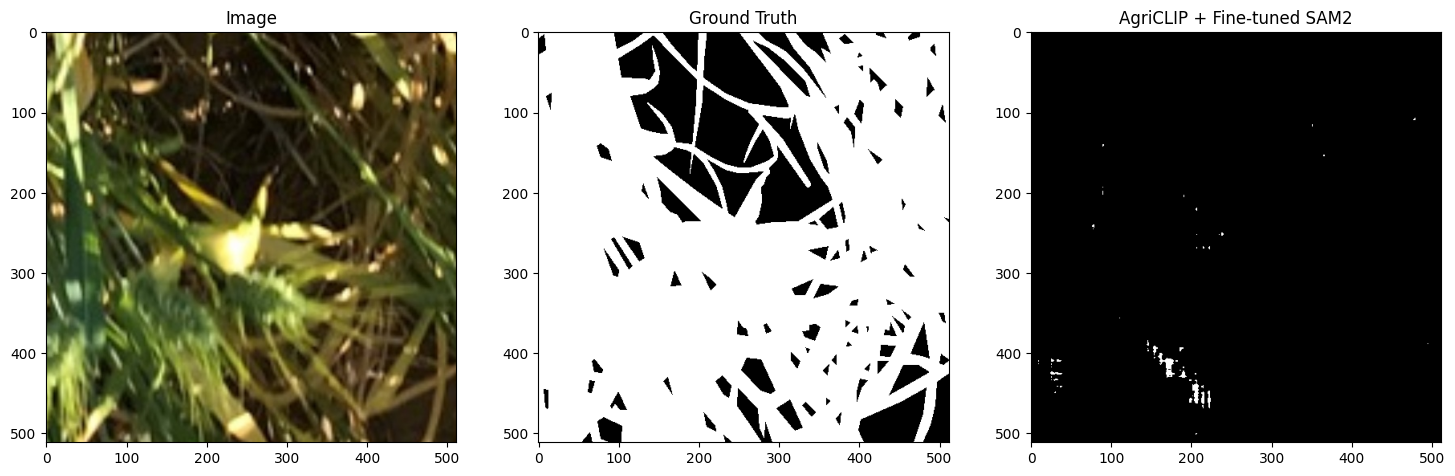

In [322]:
#Visualize Final prediction 
gt = get_mask(
    0,
    split=val_hf
)

plt.figure(figsize=(18,6))

plt.subplot(131)

plt.imshow(image)

plt.title("Image")

plt.subplot(132)

plt.imshow(gt,cmap="gray")

plt.title("Ground Truth")

plt.subplot(133)

plt.imshow(pred_mask,cmap="gray")

plt.title("AgriCLIP + Fine-tuned SAM2")

plt.show()

In [323]:
#IoU and Dice 
def compute_iou(pred,gt):

    pred = pred.astype(bool)

    gt = gt.astype(bool)

    inter = np.logical_and(
        pred,
        gt
    ).sum()

    union = np.logical_or(
        pred,
        gt
    ).sum()

    if union == 0:

        return 1.0

    return inter/union


def compute_dice(pred,gt):

    pred = pred.astype(bool)

    gt = gt.astype(bool)

    inter = np.logical_and(
        pred,
        gt
    ).sum()

    denom = pred.sum()+gt.sum()

    if denom==0:

        return 1.0

    return 2*inter/denom


print(

    "IoU:",

    compute_iou(

        pred_mask,

        gt

    )

)

print(

    "Dice:",

    compute_dice(

        pred_mask,

        gt

    )

)

IoU: 0.00395440688689917
Dice: 0.007877662291779063


In [ ]:
# Load ground truth mask for the same validation image

sample_index = 0

gt_mask = get_mask(
    sample_index,
    split=val_hf
)

print(gt_mask.shape)

(512, 512)


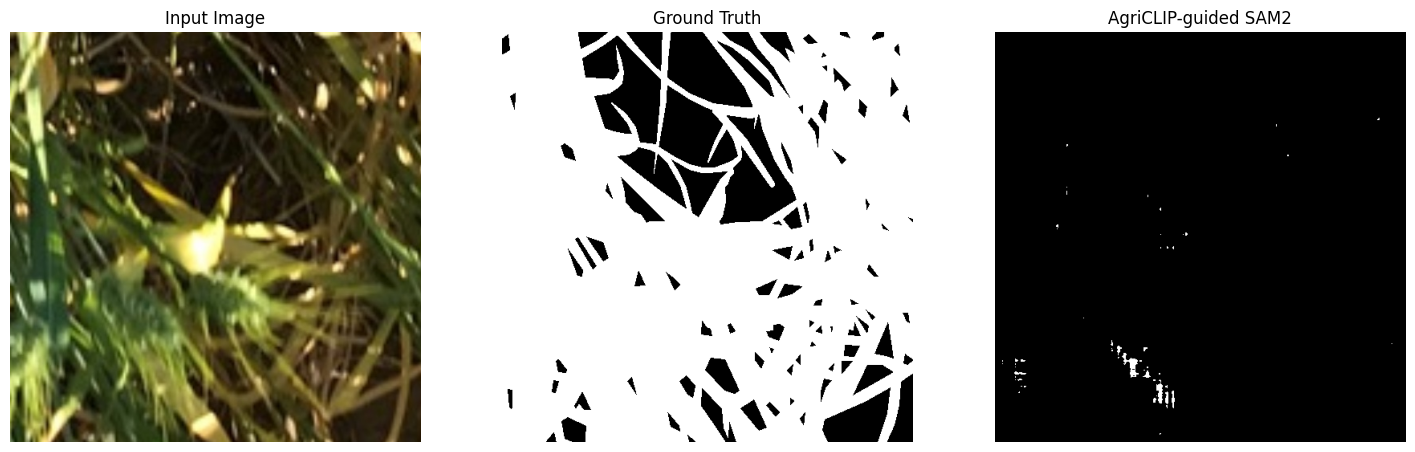

In [325]:
plt.figure(figsize=(18,6))

plt.subplot(1,3,1)
plt.imshow(image)
plt.title("Input Image")
plt.axis("off")

plt.subplot(1,3,2)
plt.imshow(gt_mask, cmap="gray")
plt.title("Ground Truth")
plt.axis("off")

plt.subplot(1,3,3)
plt.imshow(pred_mask, cmap="gray")
plt.title("AgriCLIP-guided SAM2")
plt.axis("off")

plt.show()

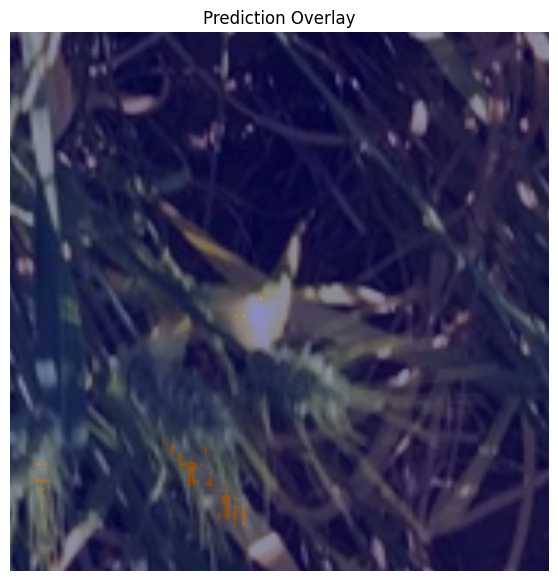

In [326]:
#Overlay prediction 
plt.figure(figsize=(7,7))

plt.imshow(image)

plt.imshow(
    pred_mask,
    cmap="jet",
    alpha=0.45
)

plt.title("Prediction Overlay")
plt.axis("off")

plt.show()

In [327]:
#IoU and Dice functions 
import numpy as np

def compute_iou(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(pred, gt).sum()

    union = np.logical_or(pred, gt).sum()

    if union == 0:
        return 1.0

    return intersection / union


def compute_dice(pred, gt):

    pred = pred.astype(bool)
    gt = gt.astype(bool)

    intersection = np.logical_and(pred, gt).sum()

    denominator = pred.sum() + gt.sum()

    if denominator == 0:
        return 1.0

    return 2 * intersection / denominator

In [328]:
#Evaluate one image 
iou = compute_iou(
    pred_mask,
    gt_mask
)

dice = compute_dice(
    pred_mask,
    gt_mask
)

print(f"IoU  : {iou:.4f}")
print(f"Dice : {dice:.4f}")

IoU  : 0.0040
Dice : 0.0079


In [329]:
print(type(attention))

if torch.is_tensor(attention):
    print(attention.shape)
    print(attention.device)

<class 'torch.Tensor'>
torch.Size([7, 7])
cuda:0


In [330]:
print("Attention min:", attention.min().item())
print("Attention max:", attention.max().item())

print("Candidate pixels:", candidate_mask.sum())

print("Prediction pixels:", pred_mask.sum())

print("Ground truth pixels:", gt_mask.sum())

Attention min: 0.0
Attention max: 0.7035609483718872
Candidate pixels: 80734
Prediction pixels: 825
Ground truth pixels: 208628


TypeError: can't convert cuda:0 device type tensor to numpy. Use Tensor.cpu() to copy the tensor to host memory first.

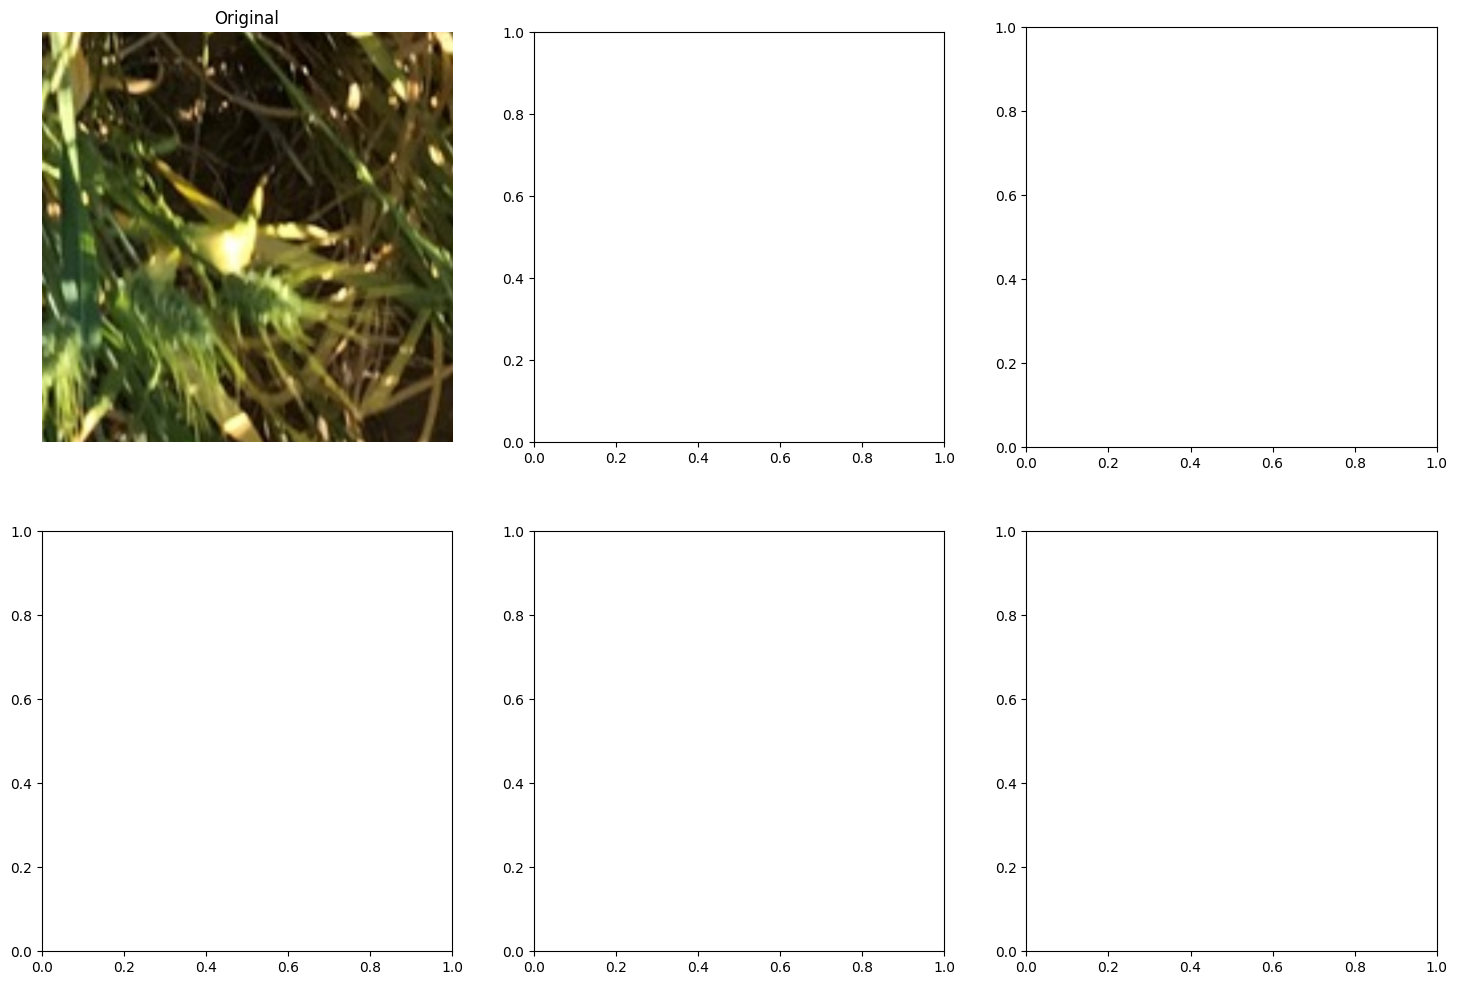

In [331]:
#Diagnostic cell 
fig, ax = plt.subplots(2,3,figsize=(18,12))

# Original
ax[0,0].imshow(image)
ax[0,0].set_title("Original")
ax[0,0].axis("off")

# Attention
ax[0,1].imshow(attention, cmap="jet")
ax[0,1].set_title("Attention")
ax[0,1].axis("off")

# Candidate mask
ax[0,2].imshow(candidate_mask, cmap="gray")
ax[0,2].set_title("Candidate Mask")
ax[0,2].axis("off")

# AutoBox
ax[1,0].imshow(image)

x0,y0,x1,y1 = auto_box

rect = plt.Rectangle(
    (x0,y0),
    x1-x0,
    y1-y0,
    fill=False,
    edgecolor="red",
    linewidth=2
)

ax[1,0].add_patch(rect)

ax[1,0].scatter(
    points[:,0],
    points[:,1],
    c="lime",
    s=80
)

ax[1,0].set_title("Prompts")

# Prediction
ax[1,1].imshow(pred_mask,cmap="gray")
ax[1,1].set_title("SAM2 Prediction")

# GT
ax[1,2].imshow(gt_mask,cmap="gray")
ax[1,2].set_title("Ground Truth")

plt.tight_layout()
plt.show()

## Evaluation on the Entire Validation Set

This section evaluates the complete AgriCLIP-guided SAM2 pipeline on all
755 validation images.

For every image the following steps are executed:

1. Extract DINO feature map
2. Align every patch using the VegAnn aligner
3. Compute AgriCLIP positive–negative attention
4. Generate vegetation candidate mask
5. Extract AutoBox
6. Generate three positive points
7. Run fine-tuned SAM2
8. Compute IoU and Dice

In [ ]:
#Lists for evaluation 
ious = []
dices = []

global_intersection = 0
global_union = 0

global_pred_pixels = 0
global_gt_pixels = 0